# Airfoil drag-coefficient surrogate, Part 1: V1 to V12 (500-airfoil dataset)

## Setup: load data, choose inputs/target, scale inputs

In [ ]:

# Load the 500-airfoil splits
# upload airfoil_train.csv, airfoil_validation.csv, airfoil_test.csv


from pathlib import Path

try:
    from google.colab import files
    uploaded = files.upload()
    DATA_DIR = Path(".")
except ImportError:
    DATA_DIR = next(p / "data" / "processed" for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "data" / "processed" / "airfoil_train.csv").exists())

import pandas as pd
import numpy as np

train_df = pd.read_csv(DATA_DIR / "airfoil_train.csv")
val_df = pd.read_csv(DATA_DIR / "airfoil_validation.csv")
test_df = pd.read_csv(DATA_DIR / "airfoil_test.csv")

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

Saving airfoil_test.csv to airfoil_test.csv
Saving airfoil_train.csv to airfoil_train.csv
Saving airfoil_validation.csv to airfoil_validation.csv


(2911, 204)
(631, 204)
(633, 204)


In [ ]:
geometry_cols = [f"geometry_{i:03d}" for i in range(200)]

feature_cols = geometry_cols + ["alpha_deg"]
target_col = "cd"

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = val_df[feature_cols]
y_val = val_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (2911, 201) (2911,)
Validation: (631, 201) (631,)
Testing: (633, 201) (633,)


The scaler is fitted on the training rows only and then applied to validation and test, so no information from the held-out airfoils leaks into preprocessing.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to validation and test
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (2911, 201)
Validation: (631, 201)
Testing: (633, 201)


## Baseline: linear regression

checking whether a linear model on the same 201 inputs is already good enough. If it were, an MLP would not be needed.

In [ ]:
from sklearn.linear_model import LinearRegression

# Initializing model
linear_model = LinearRegression()

# Training
linear_model.fit(X_train_scaled, y_train)

# Predicting on validation data
val_pred_linear = linear_model.predict(X_val_scaled)

print("Linear Regression training completed!")

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_val, val_pred_linear)
rmse = np.sqrt(mean_squared_error(y_val, val_pred_linear))
r2 = r2_score(y_val, val_pred_linear)

print("Linear Regression - Validation Performance")
print("-------------------------------------------")
print(f"MAE:  {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²:   {r2:.6f}")

Linear Regression training completed!


Linear Regression - Validation Performance
-------------------------------------------
MAE:  0.001900
RMSE: 0.002742
R²:   -0.577755


**Result:** R² = −0.58, i.e. worse than always predicting the mean $C_d$. A nonlinear model is required.

---
## V1: first MLP (128-64-32, raw $C_d$ target)

Three ReLU hidden layers (128 → 64 → 32), Adam (lr 1e-3), MSE loss, batch 32, early stopping on validation loss (patience 20, best weights restored).The simplest standard nonlinear regressor

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,225 (141.50 KB)

 Trainable params: 36,225 (141.50 KB)

 Non-trainable params: 0 (0.00 B)

[... per-epoch training log trimmed: 236 epochs run; final epoch shown below ...]
Epoch 236/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.0224e-06 - mae: 8.1593e-04 - val_loss: 1.9641e-06 - val_mae: 9.4884e-04


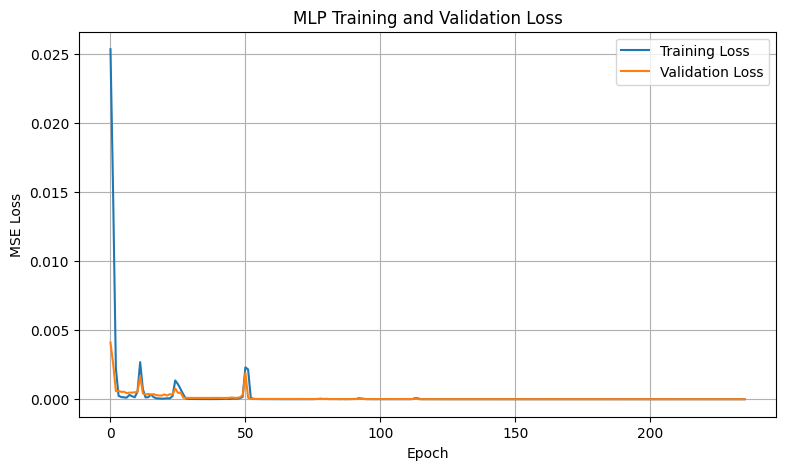

Best validation loss: 1.6493772818648722e-06
Epochs completed: 236


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
MLP - Validation Performance
--------------------------------
MAE:  0.000895
RMSE: 0.001284
R²:   0.653857


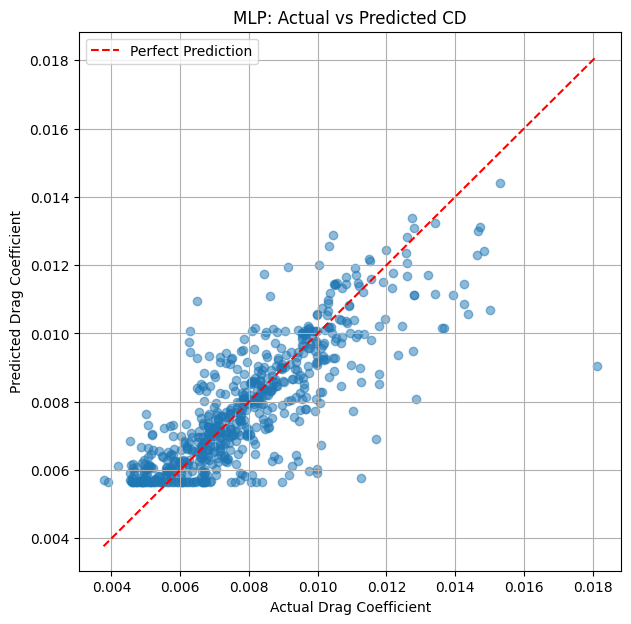

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build MLP
mlp = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),

    layers.Dense(1)
])

# Compile
mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

mlp.summary()

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = mlp.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=300,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("MLP Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

print("Best validation loss:", min(history.history["val_loss"]))
print("Epochs completed:", len(history.history["loss"]))

# Predict using the trained MLP
val_pred_mlp = mlp.predict(X_val_scaled).flatten()

# Calculate metrics
mlp_mae = mean_absolute_error(y_val, val_pred_mlp)
mlp_rmse = np.sqrt(mean_squared_error(y_val, val_pred_mlp))
mlp_r2 = r2_score(y_val, val_pred_mlp)

print("MLP - Validation Performance")
print("--------------------------------")
print(f"MAE:  {mlp_mae:.6f}")
print(f"RMSE: {mlp_rmse:.6f}")
print(f"R²:   {mlp_r2:.6f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    val_pred_mlp,
    alpha=0.5
)

# Perfect prediction reference line
min_val = min(y_val.min(), val_pred_mlp.min())
max_val = max(y_val.max(), val_pred_mlp.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Drag Coefficient")
plt.ylabel("Predicted Drag Coefficient")
plt.title("MLP: Actual vs Predicted CD")
plt.legend()
plt.grid(True)
plt.show()

**Result:** validation R² **0.654** (MAE 0.000895). A large jump from linear regression, so the MLP is the right model family.

**Observation:** the best validation loss is ~1.6×10⁻⁶. Because $C_d$ ≈ 0.008, errors, losses and gradients are all tiny numbers, which makes optimisation badly conditioned. So we need V2.


In [ ]:
# Predict on untouched test dataset
test_pred_mlp = mlp.predict(X_test_scaled).flatten()

# Calculate test metrics
test_mae = mean_absolute_error(y_test, test_pred_mlp)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred_mlp))
test_r2 = r2_score(y_test, test_pred_mlp)

print("MLP - FINAL TEST PERFORMANCE")
print("--------------------------------")
print(f"MAE:  {test_mae:.6f}")
print(f"RMSE: {test_rmse:.6f}")
print(f"R²:   {test_r2:.6f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
MLP - FINAL TEST PERFORMANCE
--------------------------------
MAE:  0.000877
RMSE: 0.001459
R²:   0.529916


---
## V2: standardise the target

Same network as V1, but we are training on $(C_d-\mu)/\sigma$ (training statistics) and converting the predictions back.

**Why:** the raw target has mean ≈ 0.008 and spread ≈ 0.002. Standardising puts it on an constant scale, so the default learning rate and initial weights are sensible and the loss is not dominated by numerical scale.

In [ ]:
# Standardise target
target_scaler = StandardScaler()

y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

y_val_scaled = target_scaler.transform(
    y_val.to_numpy().reshape(-1, 1)
)

# Reset and create fresh model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v2 = keras.Sequential([
    layers.Input(shape=(201,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

mlp_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop_v2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history_v2 = mlp_v2.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=300,
    batch_size=32,
    callbacks=[early_stop_v2],
    verbose=1
)

val_pred_v2_scaled = mlp_v2.predict(X_val_scaled)

val_pred_v2 = target_scaler.inverse_transform(
    val_pred_v2_scaled
).flatten()

print("TARGET-STANDARDISED MLP")
print("MAE:", mean_absolute_error(y_val, val_pred_v2))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v2)))
print("R2:", r2_score(y_val, val_pred_v2))

experiment_results = {
    "Original MLP": {
        "MAE": 0.000895,
        "RMSE": 0.001284,
        "R2": 0.653857
    },
    "Target Standardised MLP": {
        "MAE": 0.000801,
        "RMSE": 0.001213,
        "R2": 0.691192
    }
}

import pandas as pd

results_df = pd.DataFrame(experiment_results).T
display(results_df)

[... per-epoch training log trimmed: 64 epochs run; final epoch shown below ...]
Epoch 64/300
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0846 - mae: 0.1495 - val_loss: 0.1516 - val_mae: 0.2655


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
TARGET-STANDARDISED MLP
MAE: 0.0008010624151800873
RMSE: 0.0012130440512182143
R2: 0.6911916325370935


,MAE,RMSE,R2
Original MLP,0.000895,0.001284,0.653857
Target Standardised MLP,0.000801,0.001213,0.691192


**Result:** R² 0.654 → **0.691**, MAE 0.000895 → 0.000801. One of the two clearly real improvements in this phase.

---
## V3: regularisation (L2 + dropout), 128-64

Two hidden layers (128 → 64) with L2 weight penalty 1e-3 and dropout 0.15; patience 25.

**Why:** the training loss kept falling while validation stalled. With only 343 distinct training shapes, the network can memorise individual airfoils, so penalising large weights and adding dropout should help it generalise to unseen shapes.

In [ ]:
from tensorflow.keras import regularizers

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v3 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop_v3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history_v3 = mlp_v3.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=400,
    batch_size=32,
    callbacks=[early_stop_v3],
    verbose=1
)

val_pred_v3_scaled = mlp_v3.predict(X_val_scaled)

val_pred_v3 = target_scaler.inverse_transform(
    val_pred_v3_scaled
).flatten()

print("REGULARISED MLP")
print("MAE:", mean_absolute_error(y_val, val_pred_v3))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v3)))
print("R2:", r2_score(y_val, val_pred_v3))

[... per-epoch training log trimmed: 147 epochs run; final epoch shown below ...]
Epoch 147/400
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1559 - mae: 0.1950 - val_loss: 0.2013 - val_mae: 0.2542


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
REGULARISED MLP
MAE: 0.0007940720861999056
RMSE: 0.0011823374708195681
R2: 0.7066278917992111


**Result:** R² 0.691 → **0.707**.

---
## V4: wider network (256-128)

Same as V3 but with 256 → 128 units.

**Why:** now that regularisation limits overfitting, extra capacity is safer and may capture more of the shape-to-drag relationship.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v4 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop_v4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=25,
    restore_best_weights=True
)

history_v4 = mlp_v4.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=400,
    batch_size=32,
    callbacks=[early_stop_v4],
    verbose=1
)

val_pred_v4_scaled = mlp_v4.predict(X_val_scaled)

val_pred_v4 = target_scaler.inverse_transform(
    val_pred_v4_scaled
).flatten()

print("WIDER REGULARISED MLP")
print("MAE:", mean_absolute_error(y_val, val_pred_v4))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v4)))
print("R2:", r2_score(y_val, val_pred_v4))

[... per-epoch training log trimmed: 144 epochs run; final epoch shown below ...]
Epoch 144/400
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2335 - mae: 0.2180 - val_loss: 0.2191 - val_mae: 0.2830


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
WIDER REGULARISED MLP
MAE: 0.0007779457974752703
RMSE: 0.0011671759807647302
R2: 0.7141036584339828


**Result:** R² **0.714**: a small gain, within single-seed noise.

---
## V5: lower learning rate (3e-4), longer patience (30)

Adam learning rate 1e-3 → 3e-4; patience 30; up to 500 epochs.

**Why:** with regularisation in place the loss surface is smoother; smaller steps let the optimiser settle into a better minimum, and the longer patience stops early stopping from cutting a slow but steady improvement short.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v5 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v5.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v5 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history_v5 = mlp_v5.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=500,
    batch_size=32,
    callbacks=[early_stop_v5],
    verbose=1
)

val_pred_v5_scaled = mlp_v5.predict(X_val_scaled)

val_pred_v5 = target_scaler.inverse_transform(
    val_pred_v5_scaled
).flatten()

print("LOW LEARNING RATE MLP")
print("MAE:", mean_absolute_error(y_val, val_pred_v5))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v5)))
print("R2:", r2_score(y_val, val_pred_v5))

[... per-epoch training log trimmed: 396 epochs run; final epoch shown below ...]
Epoch 396/500
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1122 - mae: 0.1458 - val_loss: 0.1820 - val_mae: 0.2373


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
LOW LEARNING RATE MLP
MAE: 0.0007210143850467474
RMSE: 0.0011234709976184214
R2: 0.7351136092197476


**Result:** R² **0.735**, MAE 0.000721. Together with V3, this regularised, lower-LR setup is the second real improvement of this phase.

---
## V6: add a learning-rate schedule (ReduceLROnPlateau)

**What:** halve the learning rate when validation loss stalls for 10 epochs (min 1e-5); patience 40.

**Why:** a decaying step size usually fine-tunes the final weights once progress plateaus.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v6 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v6.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v6 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=40,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=10,
    min_lr=0.00001,
    verbose=1
)

history_v6 = mlp_v6.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=500,
    batch_size=32,
    callbacks=[early_stop_v6, reduce_lr],
    verbose=1
)

val_pred_v6_scaled = mlp_v6.predict(X_val_scaled)

val_pred_v6 = target_scaler.inverse_transform(
    val_pred_v6_scaled
).flatten()

print("LEARNING RATE SCHEDULING MLP")
print("MAE:", mean_absolute_error(y_val, val_pred_v6))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v6)))
print("R2:", r2_score(y_val, val_pred_v6))

[... per-epoch training log trimmed: 500 epochs run; final epoch shown below ...]
Epoch 153: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
Epoch 193: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
Epoch 205: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
Epoch 217: ReduceLROnPlateau reducing learning rate to 1.8750000890577212e-05.
Epoch 227: ReduceLROnPlateau reducing learning rate to 1e-05.
Epoch 500/500
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0977 - mae: 0.1140 - val_loss: 0.1770 - val_mae: 0.2098 - learning_rate: 1.0000e-05


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
LEARNING RATE SCHEDULING MLP
MAE: 0.0006952242995267247
RMSE: 0.001125308665183587
R2: 0.7342463483139683


**Result:** R² **0.734**: no change. 

---
## V7: smaller batches (16)

**Why:** smaller batches mean noisier gradient steps, which sometimes act as a regulariser and generalise better.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v7 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v7.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v7 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history_v7 = mlp_v7.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=500,
    batch_size=16,
    callbacks=[early_stop_v7],
    verbose=1
)

val_pred_v7_scaled = mlp_v7.predict(X_val_scaled)

val_pred_v7 = target_scaler.inverse_transform(
    val_pred_v7_scaled
).flatten()

print("BATCH SIZE 16")
print("MAE:", mean_absolute_error(y_val, val_pred_v7))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v7)))
print("R2:", r2_score(y_val, val_pred_v7))

[... per-epoch training log trimmed: 152 epochs run; final epoch shown below ...]
Epoch 152/500
182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1615 - mae: 0.1748 - val_loss: 0.1996 - val_mae: 0.2473


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
BATCH SIZE 16
MAE: 0.0007498656903259255
RMSE: 0.0011432247176489893
R2: 0.7257168514315436


**Result:** R² **0.726**: slightly worse (within noise).

---
## V8: larger batches (64)

**Why:** the opposite direction: smoother, more stable gradient estimates.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v8 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v8.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v8 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history_v8 = mlp_v8.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=500,
    batch_size=64,
    callbacks=[early_stop_v8],
    verbose=1
)

val_pred_v8_scaled = mlp_v8.predict(X_val_scaled)

val_pred_v8 = target_scaler.inverse_transform(
    val_pred_v8_scaled
).flatten()

print("BATCH SIZE 64")
print("MAE:", mean_absolute_error(y_val, val_pred_v8))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v8)))
print("R2:", r2_score(y_val, val_pred_v8))

[... per-epoch training log trimmed: 312 epochs run; final epoch shown below ...]
Epoch 312/500
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1146 - mae: 0.1341 - val_loss: 0.1864 - val_mae: 0.2226


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
BATCH SIZE 64
MAE: 0.0007029175185876206
RMSE: 0.0011004124369834937
R2: 0.745875290573828


**Result:** R² **0.746**, MAE 0.000703: the best validation score on the 500-airfoil set, so **V8 becomes the best model yet**:
`256-128 ReLU, L2 1e-3, dropout 0.15, Adam 3e-4, batch 64, early stopping (patience 30)`.

---
## V9: weaker L2 (1e-4)

**Why:** check whether the L2 penalty from V3 is now too strong and is underfitting.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v9 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.0001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.0001)
    ),

    layers.Dense(1)
])

mlp_v9.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v9 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history_v9 = mlp_v9.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=500,
    batch_size=64,
    callbacks=[early_stop_v9],
    verbose=1
)

val_pred_v9_scaled = mlp_v9.predict(X_val_scaled)

val_pred_v9 = target_scaler.inverse_transform(
    val_pred_v9_scaled
).flatten()

print("L2 = 0.0001")
print("MAE:", mean_absolute_error(y_val, val_pred_v9))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v9)))
print("R2:", r2_score(y_val, val_pred_v9))

[... per-epoch training log trimmed: 76 epochs run; final epoch shown below ...]
Epoch 76/500
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1491 - mae: 0.1924 - val_loss: 0.1843 - val_mae: 0.2629


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
L2 = 0.0001
MAE: 0.0008152484950791636
RMSE: 0.0012412133887576495
R2: 0.6766827934315223


**Result:** R² drops to **0.677**. That fall is large enough to be a real effect: L2 = 1e-3 stays.

---
## V10: less dropout (0.05)

**Why:** same question for dropout.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v10 = keras.Sequential([
    layers.Input(shape=(201,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.05),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v10.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v10 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history_v10 = mlp_v10.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=500,
    batch_size=64,
    callbacks=[early_stop_v10],
    verbose=1
)

val_pred_v10_scaled = mlp_v10.predict(X_val_scaled)

val_pred_v10 = target_scaler.inverse_transform(
    val_pred_v10_scaled
).flatten()

print("DROPOUT = 0.05")
print("MAE:", mean_absolute_error(y_val, val_pred_v10))
print("RMSE:", np.sqrt(mean_squared_error(y_val, val_pred_v10)))
print("R2:", r2_score(y_val, val_pred_v10))

[... per-epoch training log trimmed: 382 epochs run; final epoch shown below ...]
Epoch 382/500
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0929 - mae: 0.1227 - val_loss: 0.2058 - val_mae: 0.2540


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
DROPOUT = 0.05
MAE: 0.0007192362138798989
RMSE: 0.0011721757968667758
R2: 0.711649031592974


**Result:** R² **0.712**: worse than V8, so dropout 0.15 stays.

---
## V11: add four physical geometry features

Checking whether giving it additional geometries like max thickness, its chordwise location, max camber and its location (computed from the same 200 numbers) to the inputs (205 total), keeping the V8 model.

**Why:** these are the classic parameters that control airfoil drag. Handing them to the network directly might save it from having to discover them from 200 raw coordinates. The idea is it might understand the shape a little better for unseen geometries.

In [ ]:
def add_geometry_features(df):

    df = df.copy()

    geometry_cols = [
        f"geometry_{i:03d}" for i in range(200)
    ]

    geometry = df[geometry_cols].to_numpy()

    # Separate upper and lower surfaces
    upper = geometry[:, :100]
    lower = geometry[:, 100:]

    # Chordwise positions
    x = np.linspace(0, 1, 100)

    # Thickness distribution
    thickness = upper - lower

    # Camber distribution
    camber = (upper + lower) / 2

    # Maximum thickness and its location
    max_thickness_idx = np.argmax(thickness, axis=1)

    df["max_thickness"] = np.max(thickness, axis=1)

    df["thickness_location"] = x[max_thickness_idx]

    # Maximum absolute camber and its location
    max_camber_idx = np.argmax(np.abs(camber), axis=1)

    df["max_camber"] = np.max(
        np.abs(camber), axis=1
    )

    df["camber_location"] = x[max_camber_idx]

    return df

train_fe = add_geometry_features(train_df)
val_fe = add_geometry_features(val_df)
test_fe = add_geometry_features(test_df)

print("Training:", train_fe.shape)
print("Validation:", val_fe.shape)
print("Testing:", test_fe.shape)

new_feature_cols = (
    geometry_cols +
    [
        "max_thickness",
        "thickness_location",
        "max_camber",
        "camber_location",
        "alpha_deg"
    ]
)

X_train_fe = train_fe[new_feature_cols]
X_val_fe = val_fe[new_feature_cols]
X_test_fe = test_fe[new_feature_cols]

y_train_fe = train_fe["cd"]
y_val_fe = val_fe["cd"]
y_test_fe = test_fe["cd"]

print(X_train_fe.shape)
print(X_val_fe.shape)
print(X_test_fe.shape)

from sklearn.preprocessing import StandardScaler

scaler_fe = StandardScaler()

X_train_fe_scaled = scaler_fe.fit_transform(X_train_fe)
X_val_fe_scaled = scaler_fe.transform(X_val_fe)
X_test_fe_scaled = scaler_fe.transform(X_test_fe)

# Standardise target
target_scaler_fe = StandardScaler()

y_train_fe_scaled = target_scaler_fe.fit_transform(
    y_train_fe.to_numpy().reshape(-1, 1)
)

y_val_fe_scaled = target_scaler_fe.transform(
    y_val_fe.to_numpy().reshape(-1, 1)
)

print("Training:", X_train_fe_scaled.shape)
print("Validation:", X_val_fe_scaled.shape)
print("Testing:", X_test_fe_scaled.shape)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

mlp_v11 = keras.Sequential([
    layers.Input(shape=(205,)),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.15),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dense(1)
])

mlp_v11.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v11 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history_v11 = mlp_v11.fit(
    X_train_fe_scaled,
    y_train_fe_scaled,
    validation_data=(
        X_val_fe_scaled,
        y_val_fe_scaled
    ),
    epochs=500,
    batch_size=64,
    callbacks=[early_stop_v11],
    verbose=1
)

val_pred_v11_scaled = mlp_v11.predict(X_val_fe_scaled)

val_pred_v11 = target_scaler_fe.inverse_transform(
    val_pred_v11_scaled
).flatten()

print("GEOMETRY-ENHANCED MLP")
print("--------------------------------")

print("MAE:", mean_absolute_error(y_val_fe, val_pred_v11))

print("RMSE:", np.sqrt(
    mean_squared_error(y_val_fe, val_pred_v11)
))

print("R2:", r2_score(y_val_fe, val_pred_v11))

Training: (2911, 208)
Validation: (631, 208)
Testing: (633, 208)


(2911, 205)
(631, 205)
(633, 205)


Training: (2911, 205)
Validation: (631, 205)
Testing: (633, 205)


[... per-epoch training log trimmed: 417 epochs run; final epoch shown below ...]
Epoch 417/500
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1026 - mae: 0.1341 - val_loss: 0.1803 - val_mae: 0.2316


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
GEOMETRY-ENHANCED MLP
--------------------------------
MAE: 0.0007379257679783788
RMSE: 0.00115376822941189
R2: 0.7206343107526372


**Result:** R² **0.721**: no improvement over V8. The information is already contained in the 200 coordinates, so restating it does not help (Part 3 / V19 tests a much larger set of physics features and finds the same thing).

---
## Final test of the 500-set reference model (V8)

V8 was selected on validation, so it is now scored once on the untouched test airfoils.

In [ ]:
# Predict using V8
test_pred_v8_scaled = mlp_v8.predict(X_test_scaled)

# Convert back to original CD scale
test_pred_v8 = target_scaler.inverse_transform(
    test_pred_v8_scaled
).flatten()

# Final test metrics
print("FINAL MODEL: V8")
print("----------------------------")

print("MAE:",
      mean_absolute_error(y_test, test_pred_v8))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, test_pred_v8)))

print("R2:",
      r2_score(y_test, test_pred_v8))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
FINAL MODEL: V8
----------------------------
MAE: 0.0007002636752855533
RMSE: 0.001303434010575346
R2: 0.6245846340258788


### Summary of the 500-airfoil phase (original single-seed runs)

| Version | Change | Val MAE | Val RMSE | Val R² |
|---|---|---|---|---|
| Linear | baseline | 0.001900 | 0.002742 | −0.578 |
| V1 | MLP 128-64-32, raw target | 0.000895 | 0.001284 | 0.654 |
| V2 | standardised target | 0.000801 | 0.001213 | 0.691 |
| V3 | L2 1e-3 + dropout 0.15 | 0.000794 | 0.001182 | 0.707 |
| V4 | 256-128 | 0.000778 | 0.001167 | 0.714 |
| V5 | lr 3e-4, patience 30 | 0.000721 | 0.001123 | 0.735 |
| V6 | + ReduceLROnPlateau | 0.000695 | 0.001125 | 0.734 |
| V7 | batch 16 | 0.000750 | 0.001143 | 0.726 |
| **V8** | **batch 64** | **0.000703** | **0.001100** | **0.746** |
| V9 | L2 1e-4 | 0.000815 | 0.001241 | 0.677 |
| V10 | dropout 0.05 | 0.000719 | 0.001172 | 0.712 |
| V11 | + 4 geometry scalars | 0.000738 | 0.001154 | 0.721 |

V8 test: MAE 0.000700, RMSE 0.001303, R² 0.625.

**What actually mattered:**
* Standardising the target (V2) and regularisation plus a lower learning rate (V3–V5) are real gains.
* Batch size, dropout fine-tuning and the extra features (V6, V7, V10, V11) moved R² by less than the seed-to-seed noise.
* The model was still overfitting: training fit was far better than validation.

The natural next step was **more distinct airfoil shapes**, so the dataset was expanded to ~1000 airfoils.

---
## Switching to the 1000-airfoil dataset

988 airfoils: 690 train / 149 validation / 149 test (5,744 / 1,252 / 1,255 rows). All 490 airfoils of the 500 set are included with identical XFOIL values, but **the split was redrawn**, so validation and test now contain different airfoils. In Colab, upload the three `*_1000.csv` files first.

In [ ]:
import pandas as pd
import numpy as np

# Load the 1000-airfoil dataset splits
train_1000 = pd.read_csv(DATA_DIR / "airfoil_train_1000.csv")
val_1000 = pd.read_csv(DATA_DIR / "airfoil_validation_1000.csv")
test_1000 = pd.read_csv(DATA_DIR / "airfoil_test_1000.csv")

# Display dataset dimensions
print("Training set:", train_1000.shape)
print("Validation set:", val_1000.shape)
print("Testing set:", test_1000.shape)

# Check unique airfoils
print("\nUnique airfoils:")
print("Training:", train_1000["airfoil"].nunique())
print("Validation:", val_1000["airfoil"].nunique())
print("Testing:", test_1000["airfoil"].nunique())

# Check missing values
print("\nMissing values:")
print("Training:", train_1000.isnull().sum().sum())
print("Validation:", val_1000.isnull().sum().sum())
print("Testing:", test_1000.isnull().sum().sum())

from sklearn.preprocessing import StandardScaler

# Define features
geometry_cols_1000 = [f"geometry_{i:03d}" for i in range(200)]
feature_cols_1000 = geometry_cols_1000 + ["alpha_deg"]

# Separate input features
X_train_1000 = train_1000[feature_cols_1000]
X_val_1000 = val_1000[feature_cols_1000]
X_test_1000 = test_1000[feature_cols_1000]

# Separate target
y_train_1000 = train_1000["cd"]
y_val_1000 = val_1000["cd"]
y_test_1000 = test_1000["cd"]

# Scale input features
input_scaler_1000 = StandardScaler()

X_train_1000_scaled = input_scaler_1000.fit_transform(X_train_1000)
X_val_1000_scaled = input_scaler_1000.transform(X_val_1000)
X_test_1000_scaled = input_scaler_1000.transform(X_test_1000)

# Scale target
target_scaler_1000 = StandardScaler()

y_train_1000_scaled = target_scaler_1000.fit_transform(
    y_train_1000.to_numpy().reshape(-1, 1)
)

y_val_1000_scaled = target_scaler_1000.transform(
    y_val_1000.to_numpy().reshape(-1, 1)
)

print("Training input:", X_train_1000_scaled.shape)
print("Validation input:", X_val_1000_scaled.shape)
print("Testing input:", X_test_1000_scaled.shape)

print("Training target:", y_train_1000_scaled.shape)
print("Validation target:", y_val_1000_scaled.shape)

Training set: (5744, 204)
Validation set: (1252, 204)
Testing set: (1255, 204)

Unique airfoils:
Training: 690
Validation: 149
Testing: 149

Missing values:
Training: 0
Validation: 0
Testing: 0


Training input: (5744, 201)
Validation input: (1252, 201)
Testing input: (1255, 201)
Training target: (5744, 1)
Validation target: (1252, 1)


## V12: the V8 recipe on the 1000-airfoil dataset

**What:** exactly the V8 network and training settings, refitted on the new training split (the scalers are refitted on the new training split too).

**Why:** establish a baseline on the new data before changing the model, so that any change in performance can be attributed to the data.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │        51,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,737 (331.00 KB)

 Trainable params: 84,737 (331.00 KB)

 Non-trainable params: 0 (0.00 B)

[... per-epoch training log trimmed: 216 epochs run; final epoch shown below ...]
Epoch 216/500
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1575 - mae: 0.1925 - val_loss: 0.4512 - val_mae: 0.2787


180/180 ━━━━━━━━━━━━━━━━━━━━ 0s 987us/step
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
V12 MODEL PERFORMANCE

TRAINING PERFORMANCE
-----------------------------------
MAE  : 0.000537
RMSE : 0.001001
R²   : 0.8803

VALIDATION PERFORMANCE
-----------------------------------
MAE  : 0.000783
RMSE : 0.001742
R²   : 0.6250

TRAINING INFORMATION
-----------------------------------
Epochs completed : 216
Best epoch      : 186


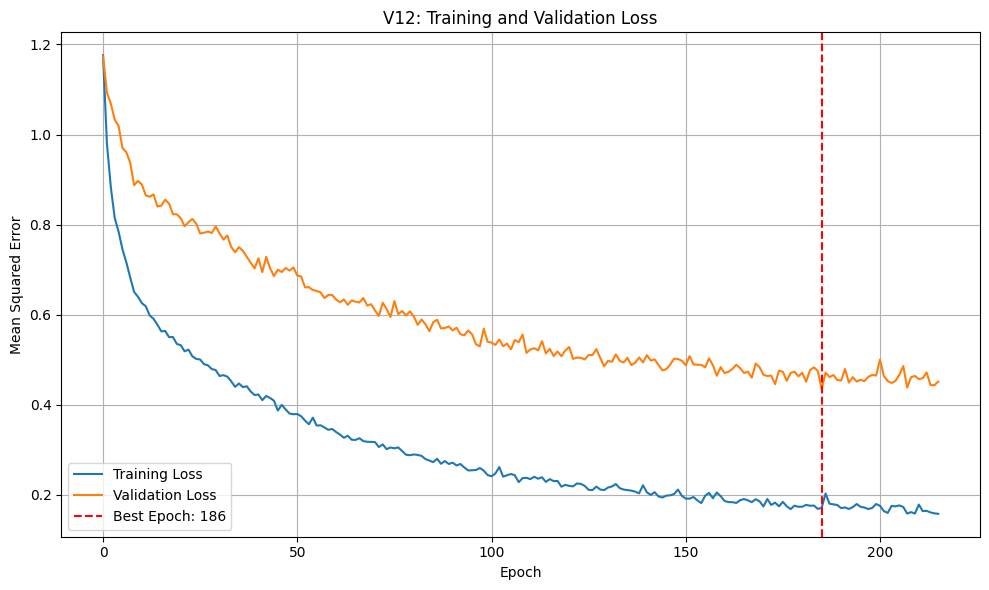

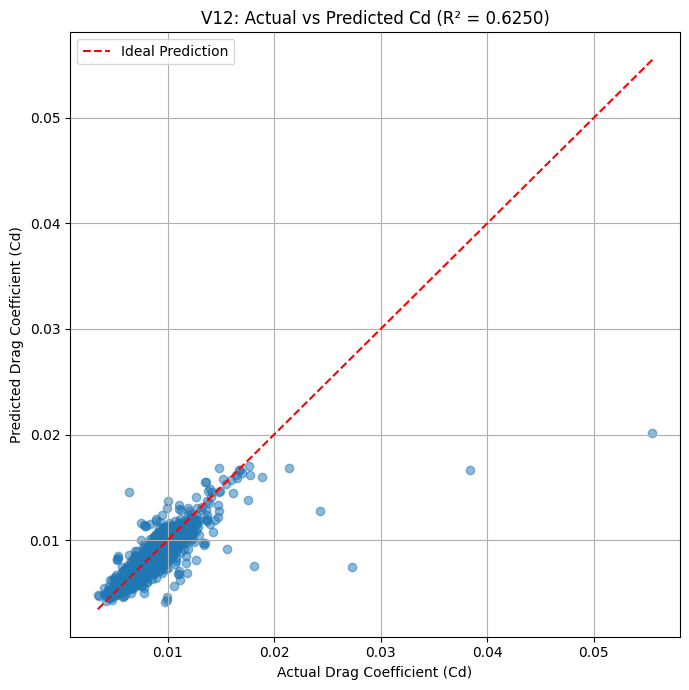

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build V12
mlp_v12 = Sequential([
    Input(shape=(201,)),

    Dense(256, activation="relu", kernel_regularizer=l2(0.001)),
    Dropout(0.15),

    Dense(128, activation="relu", kernel_regularizer=l2(0.001)),

    Dense(1)
])

# Compile
mlp_v12.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

# Early stopping
early_stopping_v12 = EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

# Display architecture
mlp_v12.summary()

history_v12 = mlp_v12.fit(
    X_train_1000_scaled,
    y_train_1000_scaled,
    validation_data=(
        X_val_1000_scaled,
        y_val_1000_scaled
    ),
    epochs=500,
    batch_size=64,
    callbacks=[early_stopping_v12],
    verbose=1
)


# V12: MODEL EVALUATION
# Neural Network Surrogate for Airfoil Drag Coefficient


import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# 1. PREDICTIONS

y_train_pred_scaled_v12 = mlp_v12.predict(X_train_1000_scaled)
y_val_pred_scaled_v12 = mlp_v12.predict(X_val_1000_scaled)

# Convert predictions back to original Cd scale
y_train_pred_v12 = target_scaler_1000.inverse_transform(
    y_train_pred_scaled_v12
).flatten()

y_val_pred_v12 = target_scaler_1000.inverse_transform(
    y_val_pred_scaled_v12
).flatten()

y_train_actual_v12 = y_train_1000.to_numpy()
y_val_actual_v12 = y_val_1000.to_numpy()



# 2. CALCULATE PERFORMANCE METRICS

# Training metrics
train_mae_v12 = mean_absolute_error(
    y_train_actual_v12, y_train_pred_v12
)

train_rmse_v12 = np.sqrt(mean_squared_error(
    y_train_actual_v12, y_train_pred_v12
))

train_r2_v12 = r2_score(
    y_train_actual_v12, y_train_pred_v12
)

# Validation metrics
val_mae_v12 = mean_absolute_error(
    y_val_actual_v12, y_val_pred_v12
)

val_rmse_v12 = np.sqrt(mean_squared_error(
    y_val_actual_v12, y_val_pred_v12
))

val_r2_v12 = r2_score(
    y_val_actual_v12, y_val_pred_v12
)



# 3. DISPLAY RESULTS

print("=" * 55)
print("V12 MODEL PERFORMANCE")
print("=" * 55)

print("\nTRAINING PERFORMANCE")
print("-" * 35)
print(f"MAE  : {train_mae_v12:.6f}")
print(f"RMSE : {train_rmse_v12:.6f}")
print(f"R²   : {train_r2_v12:.4f}")

print("\nVALIDATION PERFORMANCE")
print("-" * 35)
print(f"MAE  : {val_mae_v12:.6f}")
print(f"RMSE : {val_rmse_v12:.6f}")
print(f"R²   : {val_r2_v12:.4f}")

print("\nTRAINING INFORMATION")
print("-" * 35)
print(f"Epochs completed : {len(history_v12.history['loss'])}")
print(f"Best epoch      : {np.argmin(history_v12.history['val_loss']) + 1}")

print("=" * 55)



# 4. PLOT TRAINING AND VALIDATION LOSS


plt.figure(figsize=(10, 6))

plt.plot(
    history_v12.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_v12.history["val_loss"],
    label="Validation Loss"
)

best_epoch_v12 = np.argmin(history_v12.history["val_loss"])

plt.axvline(
    best_epoch_v12,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch_v12 + 1}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("V12: Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



# 5. ACTUAL VS PREDICTED Cd


plt.figure(figsize=(7, 7))

plt.scatter(
    y_val_actual_v12,
    y_val_pred_v12,
    alpha=0.5
)

min_val = min(y_val_actual_v12.min(), y_val_pred_v12.min())
max_val = max(y_val_actual_v12.max(), y_val_pred_v12.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual Drag Coefficient (Cd)")
plt.ylabel("Predicted Drag Coefficient (Cd)")
plt.title(f"V12: Actual vs Predicted Cd (R² = {val_r2_v12:.4f})")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Result:** validation R² **0.625** (MAE 0.000783, RMSE 0.001742), *lower* than V8's 0.746 on the 500 set, even though there is twice as much training data.

**Why it looked worse:** the two numbers come from **different validation sets**, so they are not comparable.
* The 500 set's validation airfoils had no $C_d$ above ~0.019.
* The new validation set contains **GOE09K** (C_d up to 0.055 at α = 6°, above anything in training), which alone accounts for ~34% of the validation variance.
* The new test set contains **ah93w480b**, which was a *training* airfoil in the 500 split.

When the evaluation set is held fixed, more training airfoils clearly help: training this same recipe on 172 / 345 / 690 airfoils of the new training split and scoring all three on the same validation set gives R² 0.46 / 0.60 / 0.62. 